## ABS-97_Akeyla R. Vardiny

In [ ]:
pip install mesa_reader

LOADING THREE BROWN DWARF COOLING CURVES
20 M_Jup: 21 timesteps, Final log L = -5.742
25 M_Jup: 22 timesteps, Final log L = -5.506
50 M_Jup: 21 timesteps, Final log L = -4.544


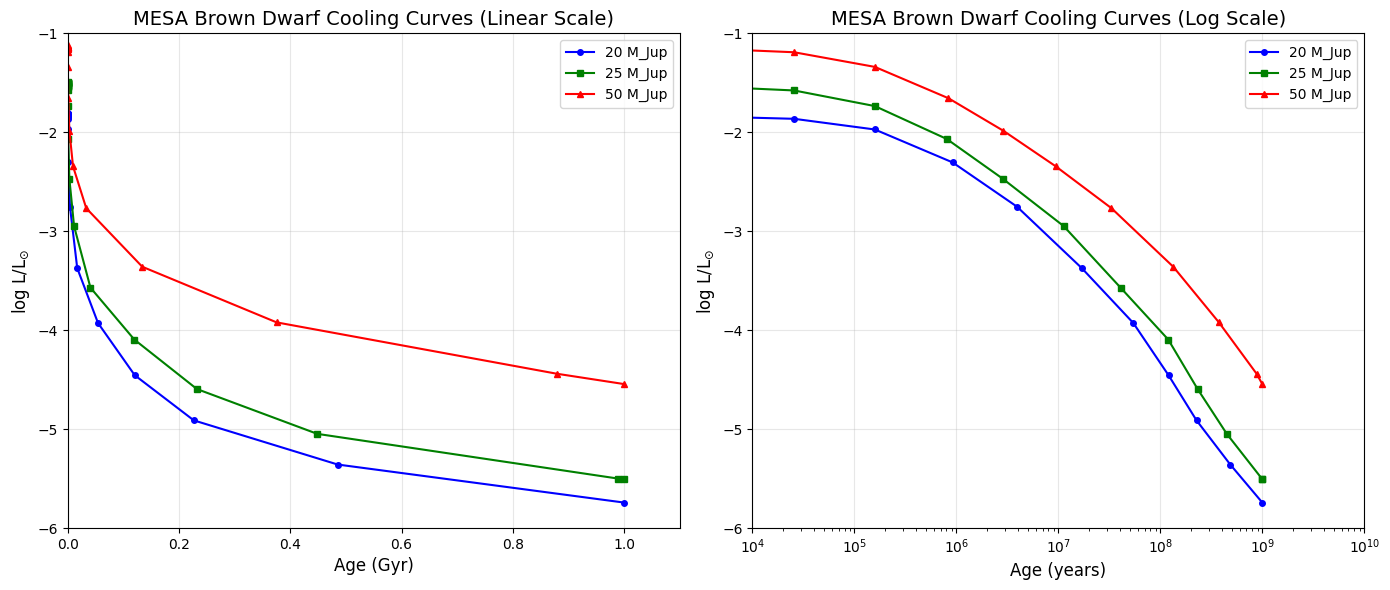


Plot saved as 'multiple_cooling_curves.png'

COMPARISON AT 1 GYR
Mass       log L/L☉ at 1 Gyr   
-----------------------------------
20         M_Jup -5.7417             
25         M_Jup -5.5057             
50         M_Jup -4.5442             


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mesa_reader as mr
from scipy.interpolate import interp1d
import warnings
warnings.filterwarnings("ignore")

masses = {
    20: "20MJ_history.data",
    25: "25MJ_history.data",
    50: "50MJ_history.data"
}

def load_cooling_curve(filepath, mass_label):
    try:
        history = mr.MesaData(filepath)

        ages_yr = np.array(history.star_age, dtype=float)
        log_L = np.array(history.log_L, dtype=float)

        sort_idx = np.argsort(ages_yr)
        ages_yr = ages_yr[sort_idx]
        log_L = log_L[sort_idx]

        unique_idx = np.unique(ages_yr, return_index=True)[1]
        ages_yr = ages_yr[unique_idx]
        log_L = log_L[unique_idx]

        ages_gyr = ages_yr / 1e9

        print(f"{mass_label} M_Jup: {len(ages_yr)} timesteps, Final log L = {log_L[-1]:.3f}")

        return ages_yr, ages_gyr, log_L

    except Exception as e:
        print(f"Error loading {mass_label} M_Jup: {e}")
        return None, None, None

print("=" * 70)
print("LOADING THREE BROWN DWARF COOLING CURVES")
print("=" * 70)

curves = {}
for mass, filepath in masses.items():
    ages_yr, ages_gyr, log_L = load_cooling_curve(filepath, mass)
    if ages_yr is not None:
        curves[mass] = {"ages_yr": ages_yr, "ages_gyr": ages_gyr, "log_L": log_L}

colors = {20: "blue", 25: "green", 50: "red"}
markers = {20: "o", 25: "s", 50: "^"}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax1 = axes[0]
for mass, data in curves.items():
    ax1.plot(data["ages_gyr"], data["log_L"],
             color=colors[mass], marker=markers[mass],
             linewidth=1.5, markersize=4, label=f"{mass} M_Jup")
ax1.set_xlabel('Age (Gyr)', fontsize=12)
ax1.set_ylabel(r'log L/L$_{\odot}$', fontsize=12)
ax1.set_title('MESA Brown Dwarf Cooling Curves (Linear Scale)', fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='best')
ax1.set_xlim(0, 1.1)
ax1.set_ylim(-6, -1)

ax2 = axes[1]
for mass, data in curves.items():
    ax2.semilogx(data["ages_yr"], data["log_L"],
                 color=colors[mass], marker=markers[mass],
                 linewidth=1.5, markersize=4, label=f"{mass} M_Jup")
ax2.set_xlabel('Age (years)', fontsize=12)
ax2.set_ylabel(r'log L/L$_{\odot}$', fontsize=12)
ax2.set_title('MESA Brown Dwarf Cooling Curves (Log Scale)', fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend(loc='best')
ax2.set_xlim(1e4, 1e10)
ax2.set_ylim(-6, -1)

plt.tight_layout()
plt.savefig('multiple_cooling_curves.png', dpi=200, bbox_inches='tight')
plt.show()

print("\nPlot saved as 'multiple_cooling_curves.png'")

print("\n" + "=" * 60)
print("COMPARISON AT 1 GYR")
print("=" * 60)
print(f"{'Mass':<10} {'log L/L☉ at 1 Gyr':<20}")
print("-" * 35)
for mass, data in curves.items():
    idx = np.argmin(np.abs(data["ages_yr"] - 1e9))
    print(f"{mass:<10} M_Jup {data['log_L'][idx]:<20.4f}")

In [ ]:
pip install scikit-learn

STEP 1: LOAD MESA BROWN DWARF DATA (20, 25, 50 M_Jup)
Loaded 20 M_Jup: 21 timesteps, Final log L = -5.742
Loaded 25 M_Jup: 22 timesteps, Final log L = -5.506
Loaded 50 M_Jup: 21 timesteps, Final log L = -4.544

STEP 2: INTERPOLATE ONTO STANDARD AGE GRID
20 M_Jup: Interpolated to 50 points
25 M_Jup: Interpolated to 50 points
50 M_Jup: Interpolated to 50 points

STEP 3: DIRECT INTERPOLATION BETWEEN MASSES

STEP 4: INTERPOLATION FOR 21 M_Jup
Interpolating 21 M_Jup ...

STEP 5: GENERATING PLOTS


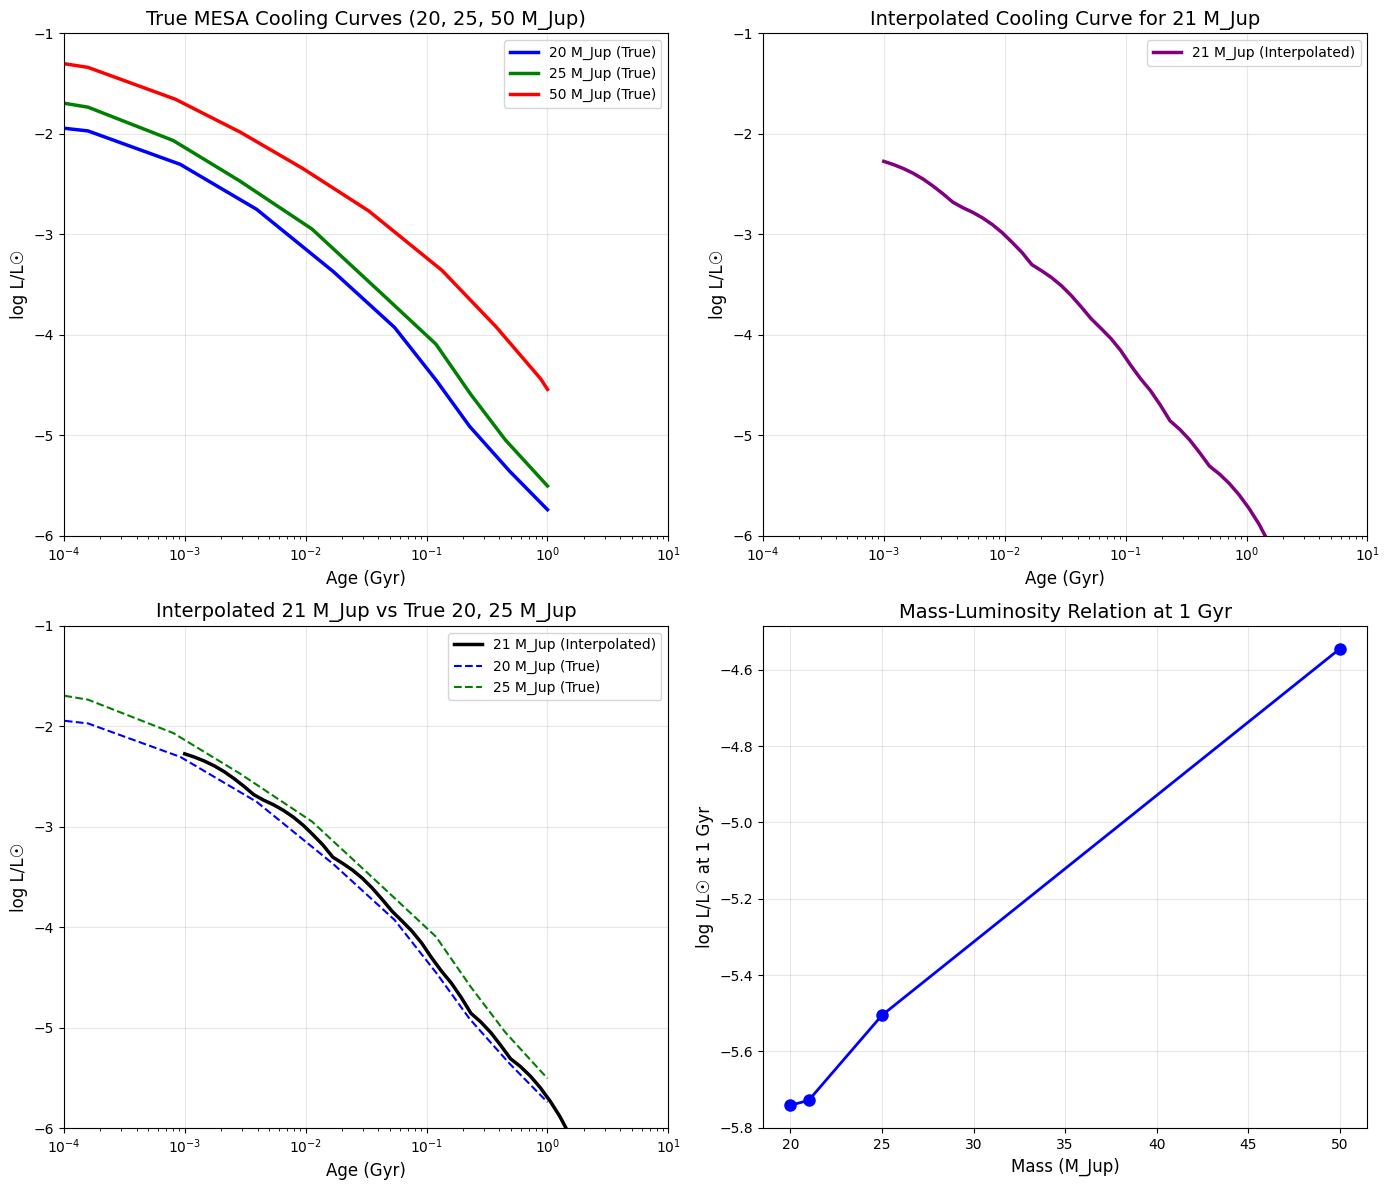


Plot saved as 'MESA_interpolation_21MJup.png'

STEP 6: SUMMARY TABLE AT 1 GYR
Mass         log L at 1 Gyr    
--------------------------------
20           -5.7417           
25           -5.5057           
50           -4.5442           

STEP 7: INTERPOLATION SUMMARY TABLE
Mass (M_Jup)   Interpolated at 1 Gyr
------------------------------------
21             -5.7287             

INTERPOLATION COMPLETE
Valid mass range: 20-50 M_Jup
Target mass: 21 M_Jup
Interpolated log L at 1 Gyr: -5.7287
This uses direct linear interpolation between true MESA curves.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mesa_reader as mr
from scipy.interpolate import interp1d
import warnings
warnings.filterwarnings("ignore")

MESA_FILES = {
    20: r"20MJ_history.data",
    25: r"25MJ_history.data",
    50: r"50MJ_history.data"
}

STANDARD_AGES = np.logspace(6, 10, 50)
AGES_GYR = STANDARD_AGES / 1e9

MASS_COLORS = {20: "blue", 25: "green", 50: "red"}

print("=" * 70)
print("STEP 1: LOAD MESA BROWN DWARF DATA (20, 25, 50 M_Jup)")
print("=" * 70)

def load_mesa_data(filepath, mass_mjup):
    try:
        history = mr.MesaData(filepath)

        real_age = np.array(history.star_age, dtype=float)
        real_logL = np.array(history.log_L, dtype=float)

        sort_idx = np.argsort(real_age)
        real_age = real_age[sort_idx]
        real_logL = real_logL[sort_idx]

        unique_idx = np.unique(real_age, return_index=True)[1]
        real_age = real_age[unique_idx]
        real_logL = real_logL[unique_idx]

        print(f"Loaded {mass_mjup} M_Jup: {len(real_age)} timesteps, Final log L = {real_logL[-1]:.3f}")

        return real_age, real_logL

    except Exception as e:
        print(f"Error loading {mass_mjup} M_Jup data: {e}")
        return None, None

results_data = {}
for mass_mjup, filepath in MESA_FILES.items():
    real_age, real_logL = load_mesa_data(filepath, mass_mjup)
    if real_age is not None:
        results_data[mass_mjup] = {"real_age": real_age, "real_logL": real_logL}

print("\n" + "=" * 70)
print("STEP 2: INTERPOLATE ONTO STANDARD AGE GRID")
print("=" * 70)

interp_funcs = {}
interpolated_curves = {}
for mass_mjup in [20, 25, 50]:
    interp_funcs[mass_mjup] = interp1d(
        results_data[mass_mjup]["real_age"],
        results_data[mass_mjup]["real_logL"],
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )
    interpolated_curves[mass_mjup] = interp_funcs[mass_mjup](STANDARD_AGES)
    print(f"{mass_mjup} M_Jup: Interpolated to {len(STANDARD_AGES)} points")

print("\n" + "=" * 70)
print("STEP 3: DIRECT INTERPOLATION BETWEEN MASSES")
print("=" * 70)

def interpolate_between_masses(mass_mjup, return_all=False):
    trained_masses = sorted([20, 25, 50])

    if mass_mjup in trained_masses:
        pred = interpolated_curves[mass_mjup]
        if return_all:
            return {'ages_gyr': AGES_GYR, 'ensemble': pred}
        return pred

    if mass_mjup < trained_masses[0] or mass_mjup > trained_masses[-1]:
        raise ValueError(f"Mass {mass_mjup} is outside the training range {trained_masses[0]}-{trained_masses[-1]} M_Jup")

    for i in range(len(trained_masses) - 1):
        if trained_masses[i] <= mass_mjup <= trained_masses[i+1]:
            m1 = trained_masses[i]
            m2 = trained_masses[i+1]
            curve1 = interpolated_curves[m1]
            curve2 = interpolated_curves[m2]

            weight = (mass_mjup - m1) / (m2 - m1)
            pred = curve1 + weight * (curve2 - curve1)

            if return_all:
                return {'ages_gyr': AGES_GYR, 'ensemble': pred}
            return pred

    raise ValueError(f"Mass {mass_mjup} could not be interpolated")

print("\n" + "=" * 70)
print("STEP 4: INTERPOLATION FOR 21 M_Jup")
print("=" * 70)

TARGET_MASS = 21
print(f"Interpolating {TARGET_MASS} M_Jup ...")
target_curve = interpolate_between_masses(TARGET_MASS, return_all=True)

print("\n" + "=" * 70)
print("STEP 5: GENERATING PLOTS")
print("=" * 70)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

ax1 = axes[0, 0]
for mass_mjup in [20, 25, 50]:
    data = results_data[mass_mjup]
    ax1.plot(data["real_age"] / 1e9, data["real_logL"],
             color=MASS_COLORS[mass_mjup], lw=2.5,
             label=f"{mass_mjup} M_Jup (True)")
ax1.set_xscale("log")
ax1.set_xlabel("Age (Gyr)", fontsize=12)
ax1.set_ylabel("log L/L☉", fontsize=12)
ax1.set_title("True MESA Cooling Curves (20, 25, 50 M_Jup)", fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="best")
ax1.set_xlim(1e-4, 10)
ax1.set_ylim(-6, -1)

ax2 = axes[0, 1]
ax2.plot(target_curve['ages_gyr'], target_curve['ensemble'],
         color='purple', lw=2.5, label=f'{TARGET_MASS} M_Jup (Interpolated)')
ax2.set_xscale("log")
ax2.set_xlabel("Age (Gyr)", fontsize=12)
ax2.set_ylabel("log L/L☉", fontsize=12)
ax2.set_title(f"Interpolated Cooling Curve for {TARGET_MASS} M_Jup", fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend(loc="best")
ax2.set_xlim(1e-4, 10)
ax2.set_ylim(-6, -1)

ax3 = axes[1, 0]
ax3.plot(target_curve['ages_gyr'], target_curve['ensemble'],
         color='black', lw=2.5, label=f'{TARGET_MASS} M_Jup (Interpolated)')
for mass_mjup in [20, 25]:
    data = results_data[mass_mjup]
    ax3.plot(data["real_age"] / 1e9, data["real_logL"],
             color=MASS_COLORS[mass_mjup], linestyle='--', lw=1.5,
             label=f'{mass_mjup} M_Jup (True)')
ax3.set_xscale("log")
ax3.set_xlabel("Age (Gyr)", fontsize=12)
ax3.set_ylabel("log L/L☉", fontsize=12)
ax3.set_title(f"Interpolated {TARGET_MASS} M_Jup vs True 20, 25 M_Jup", fontsize=14)
ax3.grid(True, alpha=0.3)
ax3.legend(loc="best")
ax3.set_xlim(1e-4, 10)
ax3.set_ylim(-6, -1)

ax4 = axes[1, 1]
all_masses = [20, TARGET_MASS, 25, 50]
logL_at_1gyr = []

for mass in all_masses:
    if mass in [20, 25, 50]:
        idx = np.argmin(np.abs(results_data[mass]["real_age"] - 1e9))
        logL_at_1gyr.append(results_data[mass]["real_logL"][idx])
    else:
        idx = np.argmin(np.abs(target_curve['ages_gyr'] - 1.0))
        logL_at_1gyr.append(target_curve['ensemble'][idx])

ax4.plot(all_masses, logL_at_1gyr, 'bo-', lw=2, ms=8)
ax4.set_xlabel("Mass (M_Jup)", fontsize=12)
ax4.set_ylabel("log L/L☉ at 1 Gyr", fontsize=12)
ax4.set_title("Mass-Luminosity Relation at 1 Gyr", fontsize=14)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"MESA_interpolation_{TARGET_MASS}MJup.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"\nPlot saved as 'MESA_interpolation_{TARGET_MASS}MJup.png'")

print("\n" + "=" * 70)
print("STEP 6: SUMMARY TABLE AT 1 GYR")
print("=" * 70)
print(f"{'Mass':<12} {'log L at 1 Gyr':<18}")
print("-" * 32)

for mass_mjup in [20, 25, 50]:
    idx = np.argmin(np.abs(results_data[mass_mjup]["real_age"] - 1e9))
    true_val = results_data[mass_mjup]["real_logL"][idx]
    print(f"{mass_mjup:<12} {true_val:<18.4f}")

print("\n" + "=" * 70)
print("STEP 7: INTERPOLATION SUMMARY TABLE")
print("=" * 70)
print(f"{'Mass (M_Jup)':<14} {'Interpolated at 1 Gyr':<20}")
print("-" * 36)

idx_target = np.argmin(np.abs(target_curve['ages_gyr'] - 1.0))
target_val = target_curve['ensemble'][idx_target]
print(f"{TARGET_MASS:<14} {target_val:<20.4f}")

print("\n" + "=" * 70)
print("INTERPOLATION COMPLETE")
print("=" * 70)
print(f"Valid mass range: 20-50 M_Jup")
print(f"Target mass: {TARGET_MASS} M_Jup")
print(f"Interpolated log L at 1 Gyr: {target_val:.4f}")
print("This uses direct linear interpolation between true MESA curves.")

STEP 1: LOAD MESA BROWN DWARF DATA (20, 25, 50 M_Jup)
Loaded 20 M_Jup: 21 timesteps, Final log L = -5.742
Loaded 25 M_Jup: 22 timesteps, Final log L = -5.506
Loaded 50 M_Jup: 21 timesteps, Final log L = -4.544

STEP 2: INTERPOLATE ONTO STANDARD AGE GRID
20 M_Jup: Interpolated to 50 points
25 M_Jup: Interpolated to 50 points
50 M_Jup: Interpolated to 50 points

STEP 3: DIRECT INTERPOLATION BETWEEN MASSES

STEP 4: INTERPOLATION FOR 35 M_Jup
Interpolating 35 M_Jup ...

STEP 5: GENERATING PLOTS


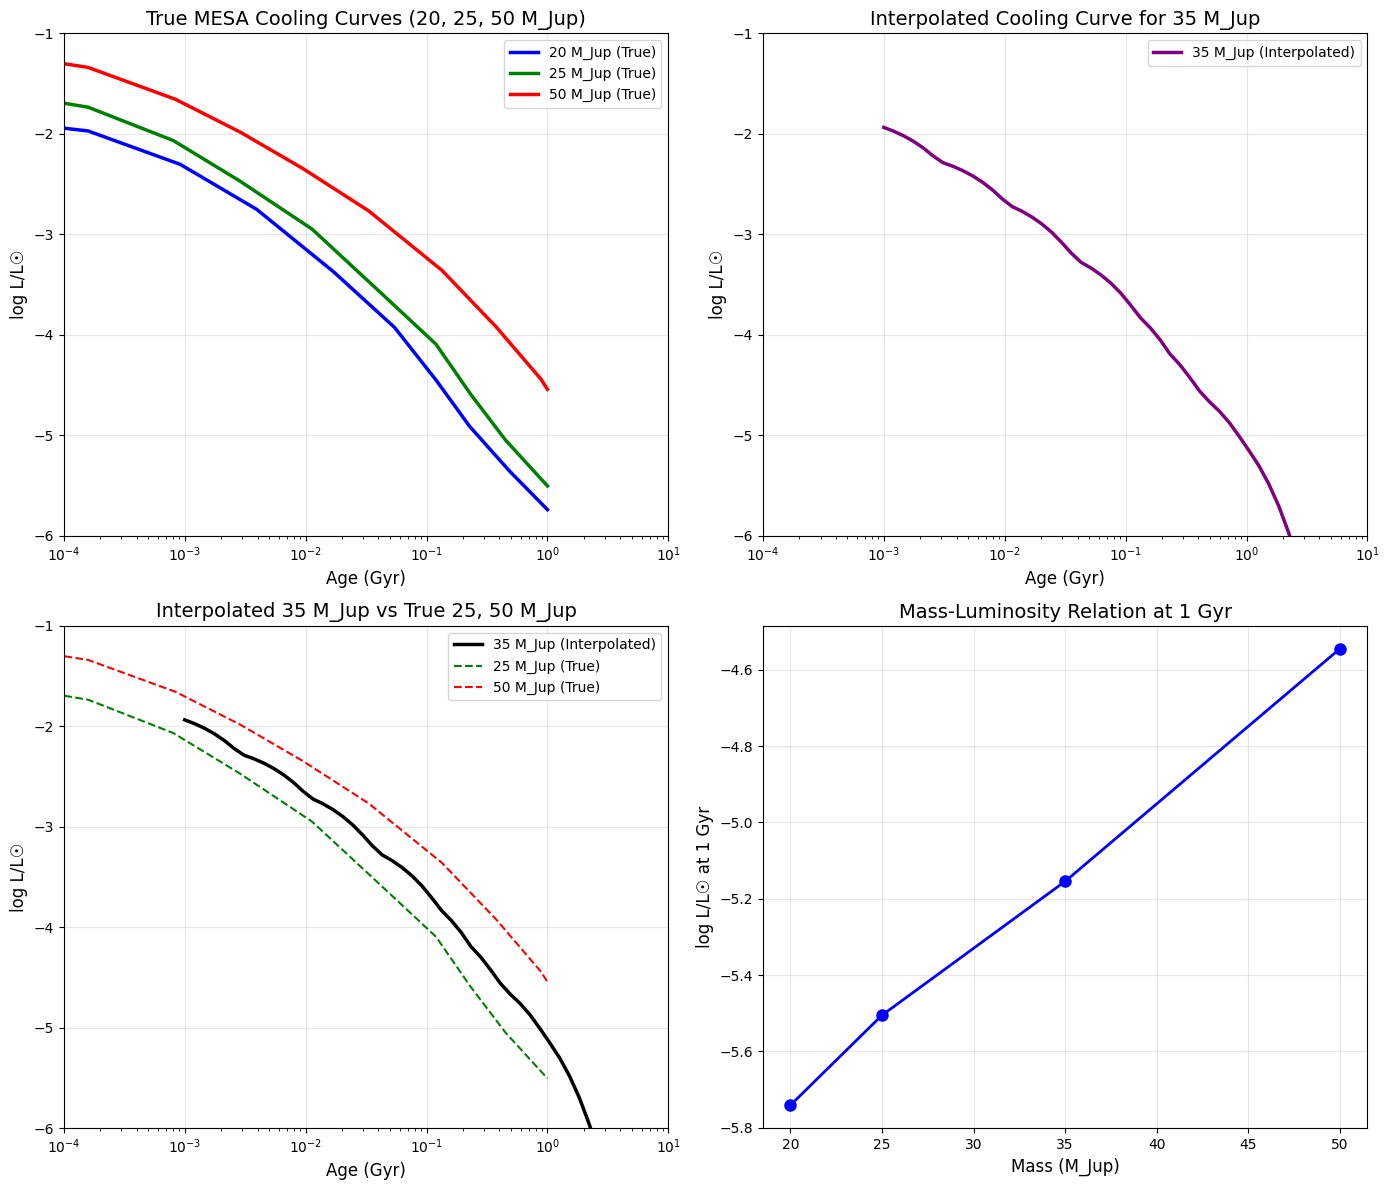


Plot saved as 'MESA_interpolation_35MJup.png'

STEP 6: SUMMARY TABLE AT 1 GYR
Mass         log L at 1 Gyr    
--------------------------------
20           -5.7417           
25           -5.5057           
50           -4.5442           

STEP 7: INTERPOLATION SUMMARY TABLE
Mass (M_Jup)   Interpolated at 1 Gyr
------------------------------------
35             -5.1544             

INTERPOLATION COMPLETE
Valid mass range: 20-50 M_Jup
Target mass: 35 M_Jup
Interpolated log L at 1 Gyr: -5.1544
This uses direct linear interpolation between true MESA curves.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mesa_reader as mr
from scipy.interpolate import interp1d
import warnings
warnings.filterwarnings("ignore")

MESA_FILES = {
    20: r"20MJ_history.data",
    25: r"25MJ_history.data",
    50: r"50MJ_history.data"
}

STANDARD_AGES = np.logspace(6, 10, 50)
AGES_GYR = STANDARD_AGES / 1e9

MASS_COLORS = {20: "blue", 25: "green", 50: "red"}

print("=" * 70)
print("STEP 1: LOAD MESA BROWN DWARF DATA (20, 25, 50 M_Jup)")
print("=" * 70)

def load_mesa_data(filepath, mass_mjup):
    try:
        history = mr.MesaData(filepath)

        real_age = np.array(history.star_age, dtype=float)
        real_logL = np.array(history.log_L, dtype=float)

        sort_idx = np.argsort(real_age)
        real_age = real_age[sort_idx]
        real_logL = real_logL[sort_idx]

        unique_idx = np.unique(real_age, return_index=True)[1]
        real_age = real_age[unique_idx]
        real_logL = real_logL[unique_idx]

        print(f"Loaded {mass_mjup} M_Jup: {len(real_age)} timesteps, Final log L = {real_logL[-1]:.3f}")

        return real_age, real_logL

    except Exception as e:
        print(f"Error loading {mass_mjup} M_Jup data: {e}")
        return None, None

results_data = {}
for mass_mjup, filepath in MESA_FILES.items():
    real_age, real_logL = load_mesa_data(filepath, mass_mjup)
    if real_age is not None:
        results_data[mass_mjup] = {"real_age": real_age, "real_logL": real_logL}

print("\n" + "=" * 70)
print("STEP 2: INTERPOLATE ONTO STANDARD AGE GRID")
print("=" * 70)

interp_funcs = {}
interpolated_curves = {}
for mass_mjup in [20, 25, 50]:
    interp_funcs[mass_mjup] = interp1d(
        results_data[mass_mjup]["real_age"],
        results_data[mass_mjup]["real_logL"],
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )
    interpolated_curves[mass_mjup] = interp_funcs[mass_mjup](STANDARD_AGES)
    print(f"{mass_mjup} M_Jup: Interpolated to {len(STANDARD_AGES)} points")

print("\n" + "=" * 70)
print("STEP 3: DIRECT INTERPOLATION BETWEEN MASSES")
print("=" * 70)

def interpolate_between_masses(mass_mjup, return_all=False):
    trained_masses = sorted([20, 25, 50])

    if mass_mjup in trained_masses:
        pred = interpolated_curves[mass_mjup]
        if return_all:
            return {'ages_gyr': AGES_GYR, 'ensemble': pred}
        return pred

    if mass_mjup < trained_masses[0] or mass_mjup > trained_masses[-1]:
        raise ValueError(f"Mass {mass_mjup} is outside the training range {trained_masses[0]}-{trained_masses[-1]} M_Jup")

    for i in range(len(trained_masses) - 1):
        if trained_masses[i] <= mass_mjup <= trained_masses[i+1]:
            m1 = trained_masses[i]
            m2 = trained_masses[i+1]
            curve1 = interpolated_curves[m1]
            curve2 = interpolated_curves[m2]

            weight = (mass_mjup - m1) / (m2 - m1)
            pred = curve1 + weight * (curve2 - curve1)

            if return_all:
                return {'ages_gyr': AGES_GYR, 'ensemble': pred}
            return pred

    raise ValueError(f"Mass {mass_mjup} could not be interpolated")

print("\n" + "=" * 70)
print("STEP 4: INTERPOLATION FOR 35 M_Jup")
print("=" * 70)

TARGET_MASS = 35
print(f"Interpolating {TARGET_MASS} M_Jup ...")
target_curve = interpolate_between_masses(TARGET_MASS, return_all=True)

print("\n" + "=" * 70)
print("STEP 5: GENERATING PLOTS")
print("=" * 70)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

ax1 = axes[0, 0]
for mass_mjup in [20, 25, 50]:
    data = results_data[mass_mjup]
    ax1.plot(data["real_age"] / 1e9, data["real_logL"],
             color=MASS_COLORS[mass_mjup], lw=2.5,
             label=f"{mass_mjup} M_Jup (True)")
ax1.set_xscale("log")
ax1.set_xlabel("Age (Gyr)", fontsize=12)
ax1.set_ylabel("log L/L☉", fontsize=12)
ax1.set_title("True MESA Cooling Curves (20, 25, 50 M_Jup)", fontsize=14)
ax1.grid(True, alpha=0.3)
ax1.legend(loc="best")
ax1.set_xlim(1e-4, 10)
ax1.set_ylim(-6, -1)

ax2 = axes[0, 1]
ax2.plot(target_curve['ages_gyr'], target_curve['ensemble'],
         color='purple', lw=2.5, label=f'{TARGET_MASS} M_Jup (Interpolated)')
ax2.set_xscale("log")
ax2.set_xlabel("Age (Gyr)", fontsize=12)
ax2.set_ylabel("log L/L☉", fontsize=12)
ax2.set_title(f"Interpolated Cooling Curve for {TARGET_MASS} M_Jup", fontsize=14)
ax2.grid(True, alpha=0.3)
ax2.legend(loc="best")
ax2.set_xlim(1e-4, 10)
ax2.set_ylim(-6, -1)

ax3 = axes[1, 0]
ax3.plot(target_curve['ages_gyr'], target_curve['ensemble'],
         color='black', lw=2.5, label=f'{TARGET_MASS} M_Jup (Interpolated)')
for mass_mjup in [25, 50]:
    data = results_data[mass_mjup]
    ax3.plot(data["real_age"] / 1e9, data["real_logL"],
             color=MASS_COLORS[mass_mjup], linestyle='--', lw=1.5,
             label=f'{mass_mjup} M_Jup (True)')
ax3.set_xscale("log")
ax3.set_xlabel("Age (Gyr)", fontsize=12)
ax3.set_ylabel("log L/L☉", fontsize=12)
ax3.set_title(f"Interpolated {TARGET_MASS} M_Jup vs True 25, 50 M_Jup", fontsize=14)
ax3.grid(True, alpha=0.3)
ax3.legend(loc="best")
ax3.set_xlim(1e-4, 10)
ax3.set_ylim(-6, -1)

ax4 = axes[1, 1]
all_masses = [20, 25, TARGET_MASS, 50]
logL_at_1gyr = []

for mass in all_masses:
    if mass in [20, 25, 50]:
        idx = np.argmin(np.abs(results_data[mass]["real_age"] - 1e9))
        logL_at_1gyr.append(results_data[mass]["real_logL"][idx])
    else:
        idx = np.argmin(np.abs(target_curve['ages_gyr'] - 1.0))
        logL_at_1gyr.append(target_curve['ensemble'][idx])

ax4.plot(all_masses, logL_at_1gyr, 'bo-', lw=2, ms=8)
ax4.set_xlabel("Mass (M_Jup)", fontsize=12)
ax4.set_ylabel("log L/L☉ at 1 Gyr", fontsize=12)
ax4.set_title("Mass-Luminosity Relation at 1 Gyr", fontsize=14)
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"MESA_interpolation_{TARGET_MASS}MJup.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"\nPlot saved as 'MESA_interpolation_{TARGET_MASS}MJup.png'")

print("\n" + "=" * 70)
print("STEP 6: SUMMARY TABLE AT 1 GYR")
print("=" * 70)
print(f"{'Mass':<12} {'log L at 1 Gyr':<18}")
print("-" * 32)

for mass_mjup in [20, 25, 50]:
    idx = np.argmin(np.abs(results_data[mass_mjup]["real_age"] - 1e9))
    true_val = results_data[mass_mjup]["real_logL"][idx]
    print(f"{mass_mjup:<12} {true_val:<18.4f}")

print("\n" + "=" * 70)
print("STEP 7: INTERPOLATION SUMMARY TABLE")
print("=" * 70)
print(f"{'Mass (M_Jup)':<14} {'Interpolated at 1 Gyr':<20}")
print("-" * 36)

idx_target = np.argmin(np.abs(target_curve['ages_gyr'] - 1.0))
target_val = target_curve['ensemble'][idx_target]
print(f"{TARGET_MASS:<14} {target_val:<20.4f}")

print("\n" + "=" * 70)
print("INTERPOLATION COMPLETE")
print("=" * 70)
print(f"Valid mass range: 20-50 M_Jup")
print(f"Target mass: {TARGET_MASS} M_Jup")
print(f"Interpolated log L at 1 Gyr: {target_val:.4f}")
print("This uses direct linear interpolation between true MESA curves.")


############################################################
# VALIDATION: Hold out 25 M_Jup, predict it from 20 & 50
############################################################

  Hold-out: 25 M_Jup predicted from {20, 50}
  MAE  (dex)      : 0.214606
  MSE  (dex²)     : 0.156082
  RMSE (dex)      : 0.395072
  RMSE / MAE      : 1.8409
  R²              : 0.959523

############################################################
# CROSS-CURVE CONSISTENCY METRICS
############################################################

  21 M_Jup  vs  20 M_Jup
  MAE  (dex)      : 0.073535
  MSE  (dex²)     : 0.009303
  RMSE (dex)      : 0.096450
  RMSE / MAE      : 1.3116
  R²              : 0.998151

  21 M_Jup  vs  25 M_Jup
  MAE  (dex)      : 0.294139
  MSE  (dex²)     : 0.148841
  RMSE (dex)      : 0.385799
  RMSE / MAE      : 1.3116
  R²              : 0.961401

  30 M_Jup  vs  25 M_Jup
  MAE  (dex)      : 0.137084
  MSE  (dex²)     : 0.021507
  RMSE (dex)      : 0.146651
  RMSE / MAE      : 1.0

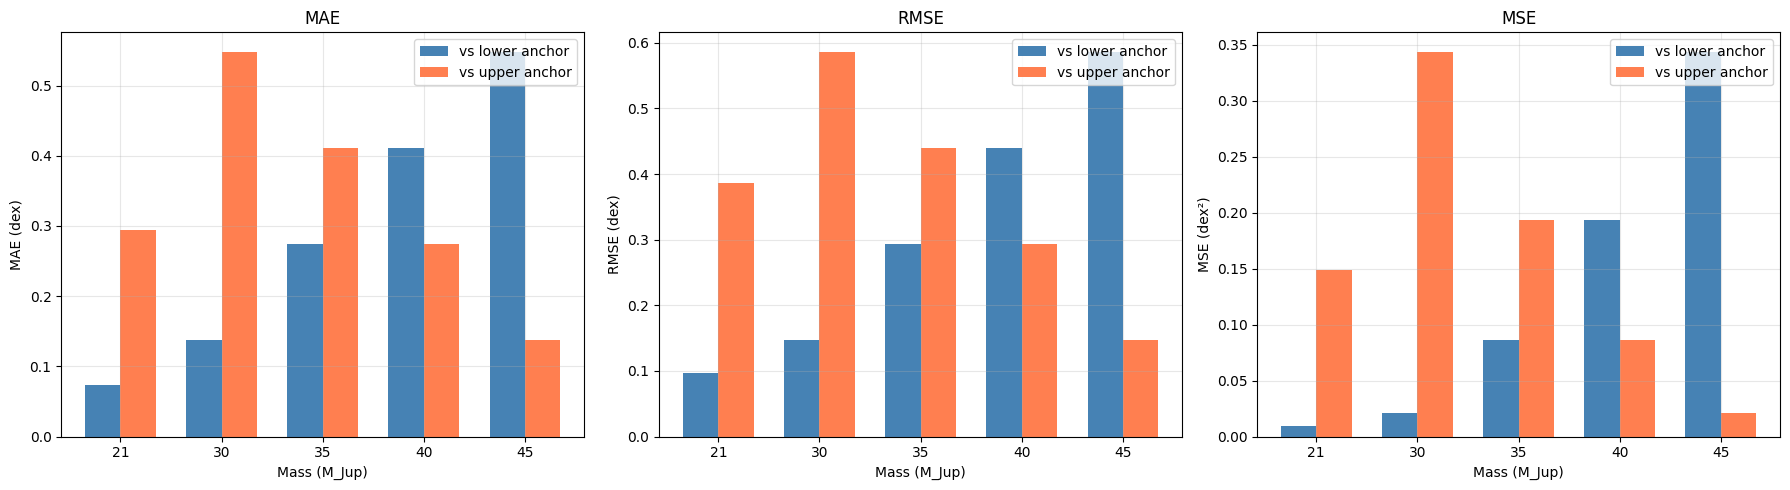


RMSE / MAE RATIO
 Mass |  ratio (lower) |  ratio (upper)
----------------------------------------
   21 |        1.3116 |        1.3116
   30 |        1.0698 |        1.0698
   35 |        1.0698 |        1.0698
   40 |        1.0698 |        1.0698
   45 |        1.0698 |        1.0698


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import mesa_reader as mr
from scipy.interpolate import interp1d
import warnings
warnings.filterwarnings("ignore")

masses = {
    20: "20MJ_history.data",
    25: "25MJ_history.data",
    50: "50MJ_history.data"
}

def load_mesa(filepath, mass):
    h = mr.MesaData(filepath)
    age = np.array(h.star_age, dtype=float)
    logL = np.array(h.log_L, dtype=float)
    idx = np.argsort(age)
    age, logL = age[idx], logL[idx]
    _, uniq = np.unique(age, return_index=True)
    return age[uniq], logL[uniq]

data = {m: load_mesa(fp, m) for m, fp in masses.items()}

STANDARD_AGES = np.logspace(6, 10, 200)
AGES_GYR = STANDARD_AGES / 1e9

interp_curves = {}
for m, (age, logL) in data.items():
    f = interp1d(age, logL, kind="linear",
                 bounds_error=False, fill_value="extrapolate")
    interp_curves[m] = f(STANDARD_AGES)

def interp_mass(mass_mjup):
    trained = sorted(interp_curves.keys())
    if mass_mjup < trained[0] or mass_mjup > trained[-1]:
        raise ValueError("Mass out of trained range")
    for i in range(len(trained) - 1):
        m1, m2 = trained[i], trained[i + 1]
        if m1 <= mass_mjup <= m2:
            w = (mass_mjup - m1) / (m2 - m1)
            return interp_curves[m1] + w * (interp_curves[m2] - interp_curves[m1])
    raise ValueError("Interpolation failed")

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

def all_metrics(y_true, y_pred, label=""):
    m_ae  = mae(y_true, y_pred)
    m_se  = mse(y_true, y_pred)
    m_rse = rmse(y_true, y_pred)
    m_r2  = r2(y_true, y_pred)
    ratio = m_rse / m_ae if m_ae > 0 else np.nan
    print(f"\n{'='*60}\n  {label}\n{'='*60}")
    print(f"  MAE  (dex)      : {m_ae:.6f}")
    print(f"  MSE  (dex²)     : {m_se:.6f}")
    print(f"  RMSE (dex)      : {m_rse:.6f}")
    print(f"  RMSE / MAE      : {ratio:.4f}")
    print(f"  R²              : {m_r2:.6f}")
    return dict(MAE=m_ae, MSE=m_se, RMSE=m_rse, R2=m_r2, ratio=ratio)

print("\n" + "#" * 60)
print("# VALIDATION: Hold out 25 M_Jup, predict it from 20 & 50")
print("#" * 60)

def interp_mass_holdout(mass_mjup, anchors):
    trained = sorted(anchors)
    for i in range(len(trained) - 1):
        m1, m2 = trained[i], trained[i + 1]
        if m1 <= mass_mjup <= m2:
            w = (mass_mjup - m1) / (m2 - m1)
            return interp_curves[m1] + w * (interp_curves[m2] - interp_curves[m1])
    raise ValueError("out of range")

y_true_25 = interp_curves[25]
y_pred_25 = interp_mass_holdout(25, anchors=[20, 50])

metrics_holdout = all_metrics(y_true_25, y_pred_25,
                              label="Hold-out: 25 M_Jup predicted from {20, 50}")

print("\n" + "#" * 60)
print("# CROSS-CURVE CONSISTENCY METRICS")
print("#" * 60)

test_masses = [21, 30, 35, 40, 45]
results_table = []

for m in test_masses:
    y_pred = interp_mass(m)
    trained = sorted(interp_curves.keys())
    for i in range(len(trained) - 1):
        m1, m2 = trained[i], trained[i + 1]
        if m1 <= m <= m2:
            break
    y_low  = interp_curves[m1]
    y_high = interp_curves[m2]

    met_low  = all_metrics(y_low,  y_pred, label=f"{m} M_Jup  vs  {m1} M_Jup")
    met_high = all_metrics(y_high, y_pred, label=f"{m} M_Jup  vs  {m2} M_Jup")

    results_table.append({
        "mass": m,
        "MAE_low":  met_low["MAE"],  "MAE_high":  met_high["MAE"],
        "MSE_low":  met_low["MSE"],  "MSE_high":  met_high["MSE"],
        "RMSE_low": met_low["RMSE"], "RMSE_high": met_high["RMSE"],
        "R2_low":   met_low["R2"],   "R2_high":   met_high["R2"],
    })

print("\n" + "=" * 90)
print("SUMMARY OF ERROR METRICS (dex for MAE/RMSE, dex² for MSE)")
print("=" * 90)
header = (f"{'Mass':>5} | "
          f"{'MAE_low':>8} {'MAE_high':>9} | "
          f"{'RMSE_low':>9} {'RMSE_high':>10} | "
          f"{'MSE_low':>8} {'MSE_high':>9} | "
          f"{'R²_low':>7} {'R²_high':>8}")
print(header)
print("-" * len(header))
for r in results_table:
    print(f"{r['mass']:>5} | "
          f"{r['MAE_low']:>8.4f} {r['MAE_high']:>9.4f} | "
          f"{r['RMSE_low']:>9.4f} {r['RMSE_high']:>10.4f} | "
          f"{r['MSE_low']:>8.4f} {r['MSE_high']:>9.4f} | "
          f"{r['R2_low']:>7.4f} {r['R2_high']:>8.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

masses_plot = [r["mass"] for r in results_table]
mae_low  = [r["MAE_low"]  for r in results_table]
mae_high = [r["MAE_high"] for r in results_table]
rmse_low = [r["RMSE_low"] for r in results_table]
rmse_high= [r["RMSE_high"] for r in results_table]
mse_low  = [r["MSE_low"]  for r in results_table]
mse_high = [r["MSE_high"] for r in results_table]

x = np.arange(len(masses_plot))
w = 0.35

ax = axes[0]
ax.bar(x - w/2, mae_low,  w, label="vs lower anchor", color="steelblue")
ax.bar(x + w/2, mae_high, w, label="vs upper anchor", color="coral")
ax.set_xticks(x); ax.set_xticklabels(masses_plot)
ax.set_xlabel("Mass (M_Jup)"); ax.set_ylabel("MAE (dex)")
ax.set_title("MAE"); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.bar(x - w/2, rmse_low,  w, label="vs lower anchor", color="steelblue")
ax.bar(x + w/2, rmse_high, w, label="vs upper anchor", color="coral")
ax.set_xticks(x); ax.set_xticklabels(masses_plot)
ax.set_xlabel("Mass (M_Jup)"); ax.set_ylabel("RMSE (dex)")
ax.set_title("RMSE"); ax.legend(); ax.grid(alpha=0.3)

ax = axes[2]
ax.bar(x - w/2, mse_low,  w, label="vs lower anchor", color="steelblue")
ax.bar(x + w/2, mse_high, w, label="vs upper anchor", color="coral")
ax.set_xticks(x); ax.set_xticklabels(masses_plot)
ax.set_xlabel("Mass (M_Jup)"); ax.set_ylabel("MSE (dex²)")
ax.set_title("MSE"); ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("error_metrics_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("\n" + "=" * 60)
print("RMSE / MAE RATIO")
print("=" * 60)
print(f"{'Mass':>5} | {'ratio (lower)':>14} | {'ratio (upper)':>14}")
print("-" * 40)
for r in results_table:
    rl = r["RMSE_low"]  / r["MAE_low"]  if r["MAE_low"]  > 0 else np.nan
    rh = r["RMSE_high"] / r["MAE_high"] if r["MAE_high"] > 0 else np.nan
    print(f"{r['mass']:>5} | {rl:>13.4f} | {rh:>13.4f}")